# Bước 5: Data Visualization
## UK Weather & Health: Weekly Deaths and Temperature (2016–2024)
---

> **Reproducibility / audit note (2026-11-13).** Run this notebook with the other notebooks and the five included data files in the **same directory**. Start with `Kernel > Restart & Run All`. The observed table has **442 real weeks**; the prepared regular grid has **469 weeks** (27 interpolated rows), and the forecasting table after lag-1 has **468 rows** (374 train / 94 observed test). This project analyzes association and **retrospective** forecasts—not causal effects or an operational heat-health warning. The original report-alignment figures and formulas are retained where they can be reproduced; any additional checks are labeled explicitly.

## 5.1 Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep', font_scale=1.1)
plt.rcParams['figure.dpi'] = 100

# Describe only real observed weeks, preserving paper denominators and total.
df = pd.read_csv('uk_weather_health_weekly_2016_2024_TOTAL_FINAL.csv',
                 parse_dates=['week_start_sat','week_start_mon','week_end'])
df = df.sort_values('week_start_mon').reset_index(drop=True)
df['year'] = df['week_start_mon'].dt.year
df['month'] = df['week_start_mon'].dt.month
df['quarter'] = df['week_start_mon'].dt.quarter
df['season'] = df['month'].map({12:'Winter',1:'Winter',2:'Winter',
    3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',
    9:'Autumn',10:'Autumn',11:'Autumn'})
df['temp_range_weekly'] = df['tasmax_max_weekly_degC']-df['tasmax_mean_weekly_degC']
df['IsSurge'] = (df['deaths_total']>df['deaths_total'].quantile(.75)).astype(int)
assert len(df)==442 and int(df['deaths_total'].sum())==4769329
print(f'Dataset: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'Các cột: {list(df.columns)}')
df.head(3)

Dataset: 442 rows × 12 columns
Các cột: ['week_start_sat', 'week_start_mon', 'week_end', 'deaths_total', 'tasmax_mean_weekly_degC', 'tasmax_max_weekly_degC', 'year', 'month', 'quarter', 'season', 'temp_range_weekly', 'IsSurge']


,week_start_sat,week_start_mon,week_end,deaths_total,tasmax_mean_weekly_degC,tasmax_max_weekly_degC,year,month,quarter,season,temp_range_weekly,IsSurge
0,2016-01-02,2016-01-04,2016-01-08,13045.0,7.363329,8.839454,2016,1,1,Winter,1.476125,1
1,2016-01-09,2016-01-11,2016-01-15,11501.0,5.132909,7.135659,2016,1,1,Winter,2.002750,0
2,2016-01-16,2016-01-18,2016-01-22,11473.0,5.359014,10.233992,2016,1,1,Winter,4.874978,0


## 5.2 Heatmap — Ma trận tương quan giữa Nhiệt độ TB, Nhiệt độ cực đại & Tử vong

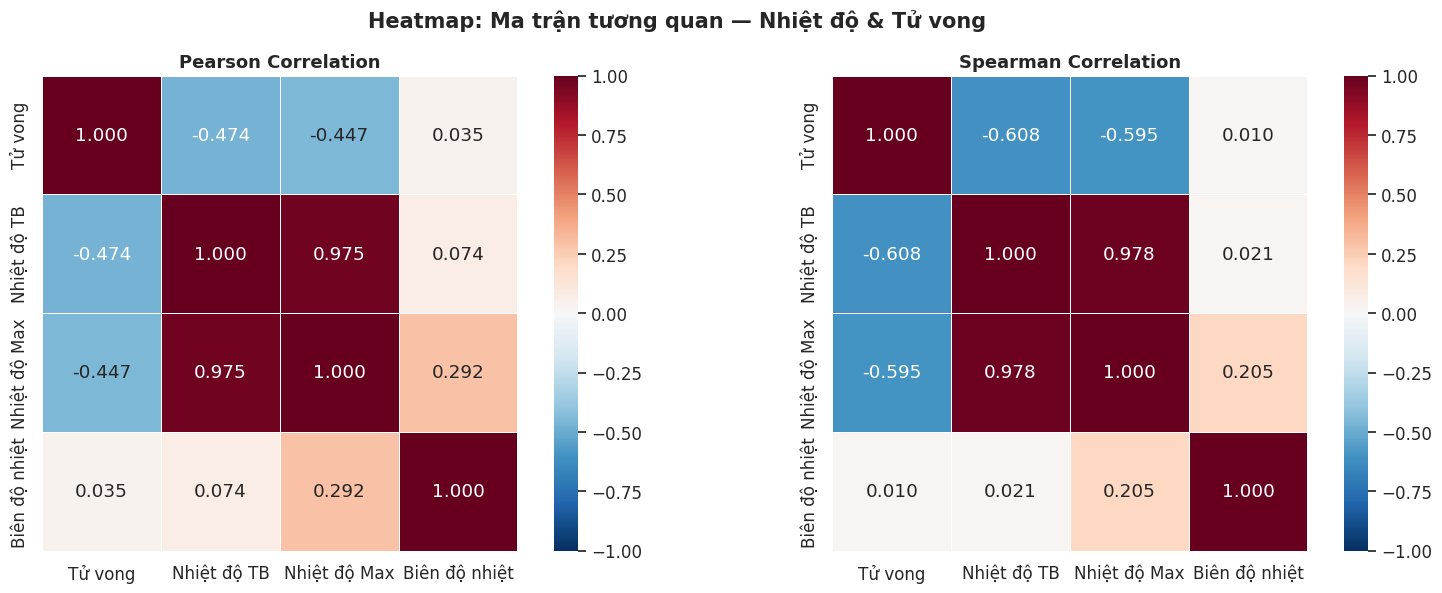

Pearson r (Tử vong vs Nhiệt độ TB) = -0.4740, p = 3.82e-26
→ Nghịch biến vừa phải: nhiệt độ tăng → tử vong giảm (do mùa đông tử vong cao)


In [2]:
corr_cols = ['deaths_total', 'tasmax_mean_weekly_degC', 'tasmax_max_weekly_degC', 'temp_range_weekly']
corr_labels = ['Tử vong', 'Nhiệt độ TB', 'Nhiệt độ Max', 'Biên độ nhiệt']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pearson
pearson = df[corr_cols].corr(method='pearson')
pearson.index = corr_labels
pearson.columns = corr_labels
sns.heatmap(pearson, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, ax=axes[0],
            linewidths=0.5, linecolor='white')
axes[0].set_title('Pearson Correlation', fontweight='bold', fontsize=13)

# Spearman
spearman = df[corr_cols].corr(method='spearman')
spearman.index = corr_labels
spearman.columns = corr_labels
sns.heatmap(spearman, annot=True, fmt='.3f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, ax=axes[1],
            linewidths=0.5, linecolor='white')
axes[1].set_title('Spearman Correlation', fontweight='bold', fontsize=13)

plt.suptitle('Heatmap: Ma trận tương quan — Nhiệt độ & Tử vong', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

r, p = stats.pearsonr(df['deaths_total'], df['tasmax_mean_weekly_degC'])
print(f'Pearson r (Tử vong vs Nhiệt độ TB) = {r:.4f}, p = {p:.2e}')
print('→ Nghịch biến vừa phải: nhiệt độ tăng → tử vong giảm (do mùa đông tử vong cao)')

## 5.3 Scatter Plot — Mối quan hệ `tasmax_mean` (X) vs `deaths_total` (Y)

This quadratic overlay is **descriptive**. Sparse very-hot weeks and unmeasured confounders prevent a causal U/J-risk or safety-threshold claim.

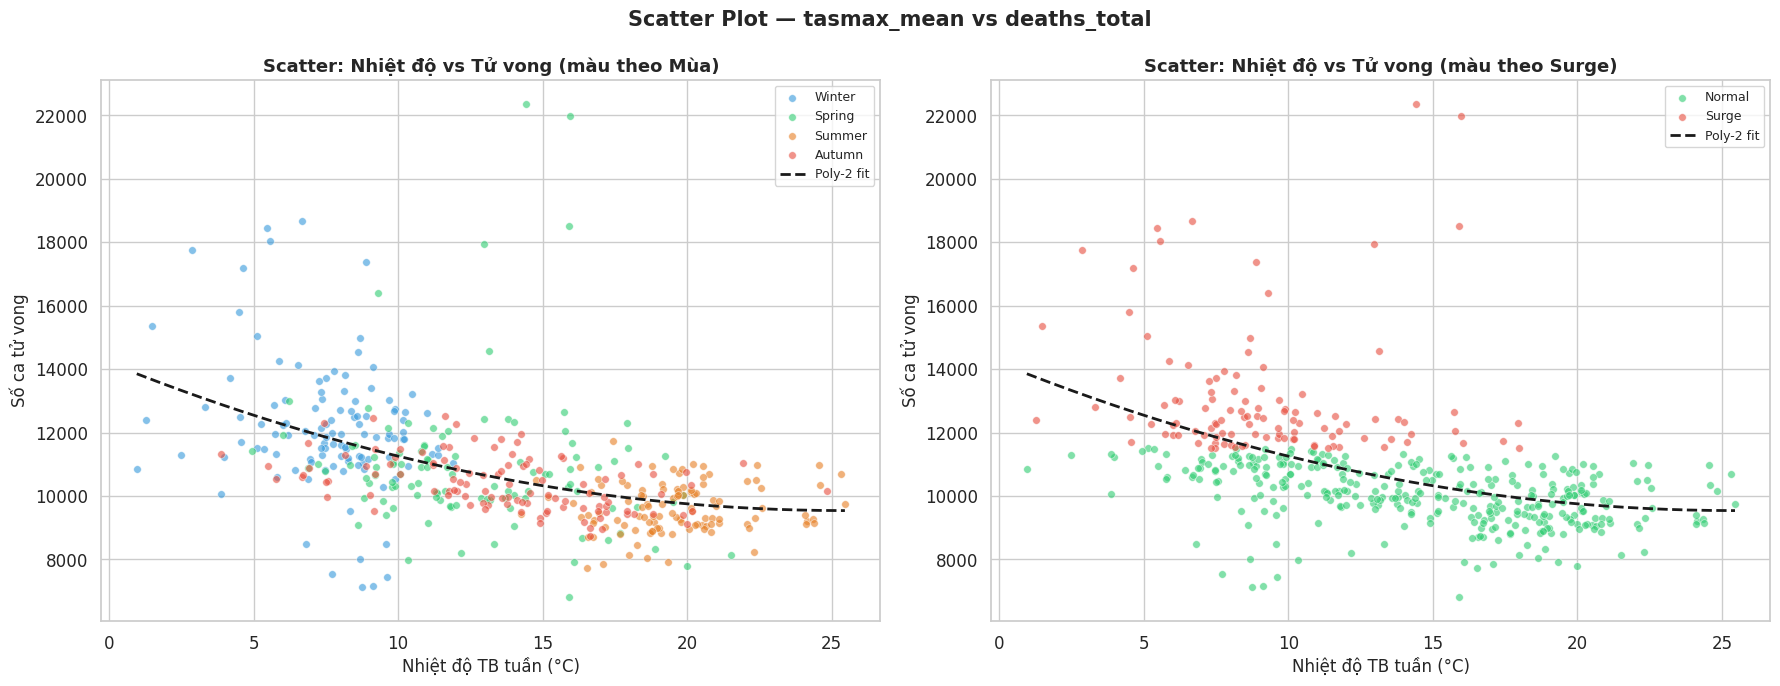

Hệ số poly bậc 2: y = 7.20x² + (-366.40)x + 14198
Descriptive vertex ~25.4°C; NOT proof of a causal U/J risk curve or medical threshold.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Scatter với màu theo mùa
season_colors = {'Winter': '#3498db', 'Spring': '#2ecc71', 'Summer': '#e67e22', 'Autumn': '#e74c3c'}
for season, color in season_colors.items():
    mask = df['season'] == season
    axes[0].scatter(df.loc[mask, 'tasmax_mean_weekly_degC'], df.loc[mask, 'deaths_total'],
                    c=color, label=season, alpha=0.6, s=30, edgecolor='white', linewidth=0.5)

# Đường hồi quy bậc 2 (polynomial) để thấy hình U/J
x = df['tasmax_mean_weekly_degC'].values
y = df['deaths_total'].values
coeffs = np.polyfit(x, y, 2)
x_fit = np.linspace(x.min(), x.max(), 200)
y_fit = np.polyval(coeffs, x_fit)
axes[0].plot(x_fit, y_fit, 'k--', linewidth=2, label=f'Poly-2 fit')

axes[0].set_xlabel('Nhiệt độ TB tuần (°C)', fontsize=12)
axes[0].set_ylabel('Số ca tử vong', fontsize=12)
axes[0].set_title('Scatter: Nhiệt độ vs Tử vong (màu theo Mùa)', fontweight='bold', fontsize=13)
axes[0].legend(fontsize=9)

# Scatter với màu theo IsSurge
surge_colors = {0: '#2ecc71', 1: '#e74c3c'}
surge_labels = {0: 'Normal', 1: 'Surge'}
for val, color in surge_colors.items():
    mask = df['IsSurge'] == val
    axes[1].scatter(df.loc[mask, 'tasmax_mean_weekly_degC'], df.loc[mask, 'deaths_total'],
                    c=color, label=surge_labels[val], alpha=0.6, s=30, edgecolor='white', linewidth=0.5)

axes[1].plot(x_fit, y_fit, 'k--', linewidth=2, label='Poly-2 fit')
axes[1].set_xlabel('Nhiệt độ TB tuần (°C)', fontsize=12)
axes[1].set_ylabel('Số ca tử vong', fontsize=12)
axes[1].set_title('Scatter: Nhiệt độ vs Tử vong (màu theo Surge)', fontweight='bold', fontsize=13)
axes[1].legend(fontsize=9)

plt.suptitle('Scatter Plot — tasmax_mean vs deaths_total', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Hệ số poly bậc 2: y = {coeffs[0]:.2f}x² + ({coeffs[1]:.2f})x + {coeffs[2]:.0f}')
if coeffs[0] > 0:
    vertex_x = -coeffs[1] / (2 * coeffs[0])
    print(f'Descriptive vertex ~{vertex_x:.1f}°C; NOT proof of a causal U/J risk curve or medical threshold.')

## 5.4 Histogram — Phân bố số ca tử vong hàng tuần

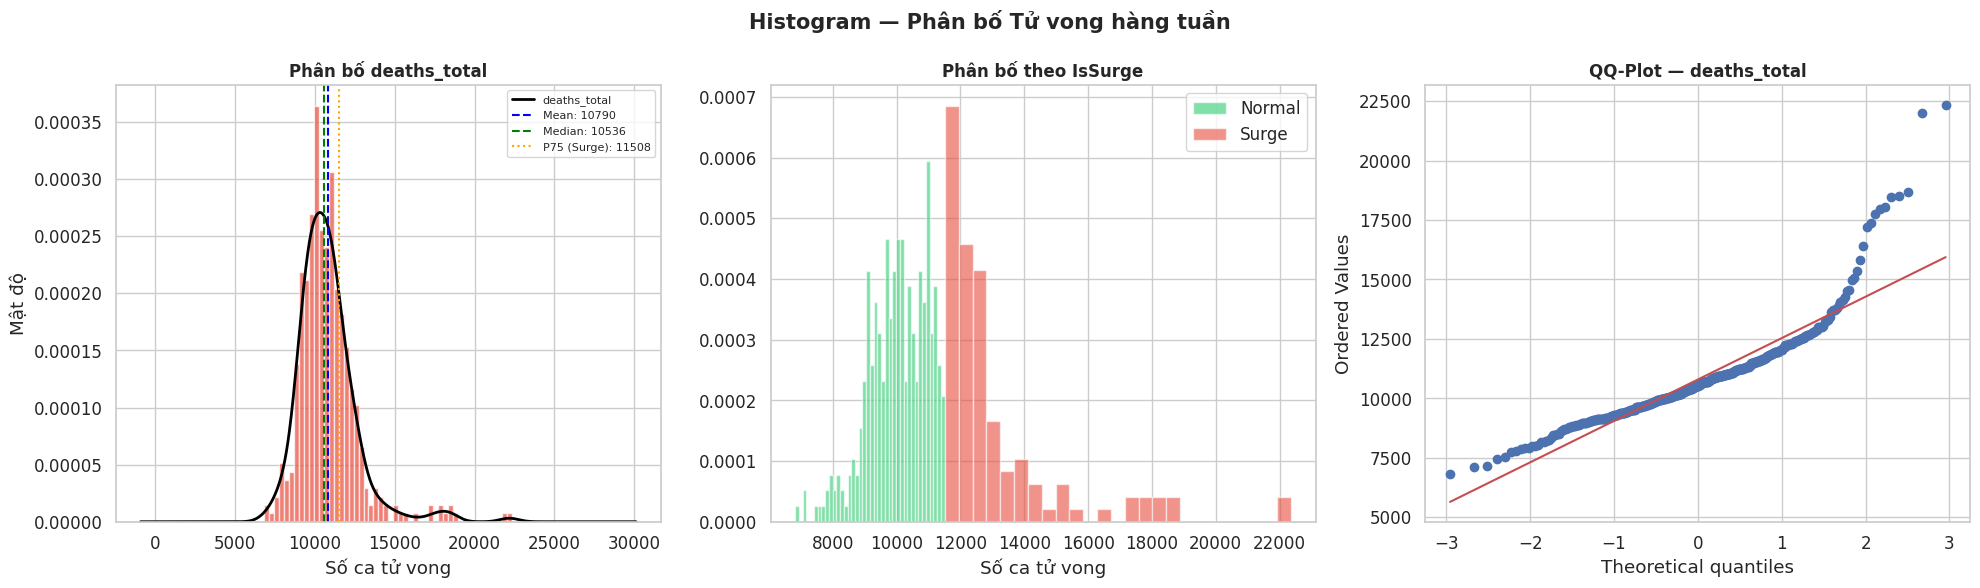

Skewness = 2.120 (lệch phải), Kurtosis = 8.379 (đuôi dày — do COVID outliers)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Histogram chung
axes[0].hist(df['deaths_total'], bins=50, color='#e74c3c', edgecolor='white', alpha=0.7, density=True)
df['deaths_total'].plot.kde(ax=axes[0], color='black', linewidth=2)
axes[0].axvline(df['deaths_total'].mean(), color='blue', linestyle='--',
                label=f'Mean: {df["deaths_total"].mean():.0f}')
axes[0].axvline(df['deaths_total'].median(), color='green', linestyle='--',
                label=f'Median: {df["deaths_total"].median():.0f}')
axes[0].axvline(df['deaths_total'].quantile(0.75), color='orange', linestyle=':',
                label=f'P75 (Surge): {df["deaths_total"].quantile(0.75):.0f}')
axes[0].set_title('Phân bố deaths_total', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Số ca tử vong')
axes[0].set_ylabel('Mật độ')
axes[0].legend(fontsize=8)

# Histogram theo IsSurge
axes[1].hist(df[df['IsSurge']==0]['deaths_total'], bins=40, color='#2ecc71', alpha=0.6,
             label='Normal', edgecolor='white', density=True)
axes[1].hist(df[df['IsSurge']==1]['deaths_total'], bins=25, color='#e74c3c', alpha=0.6,
             label='Surge', edgecolor='white', density=True)
axes[1].set_title('Phân bố theo IsSurge', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Số ca tử vong')
axes[1].legend()

# QQ-plot
stats.probplot(df['deaths_total'], dist='norm', plot=axes[2])
axes[2].set_title('QQ-Plot — deaths_total', fontweight='bold', fontsize=12)

plt.suptitle('Histogram — Phân bố Tử vong hàng tuần', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

skew = df['deaths_total'].skew()
kurt = df['deaths_total'].kurtosis()
print(f'Skewness = {skew:.3f} (lệch phải), Kurtosis = {kurt:.3f} (đuôi dày — do COVID outliers)')

## 5.5 Bar Chart — Tổng số tử vong theo từng năm (2016–2024)

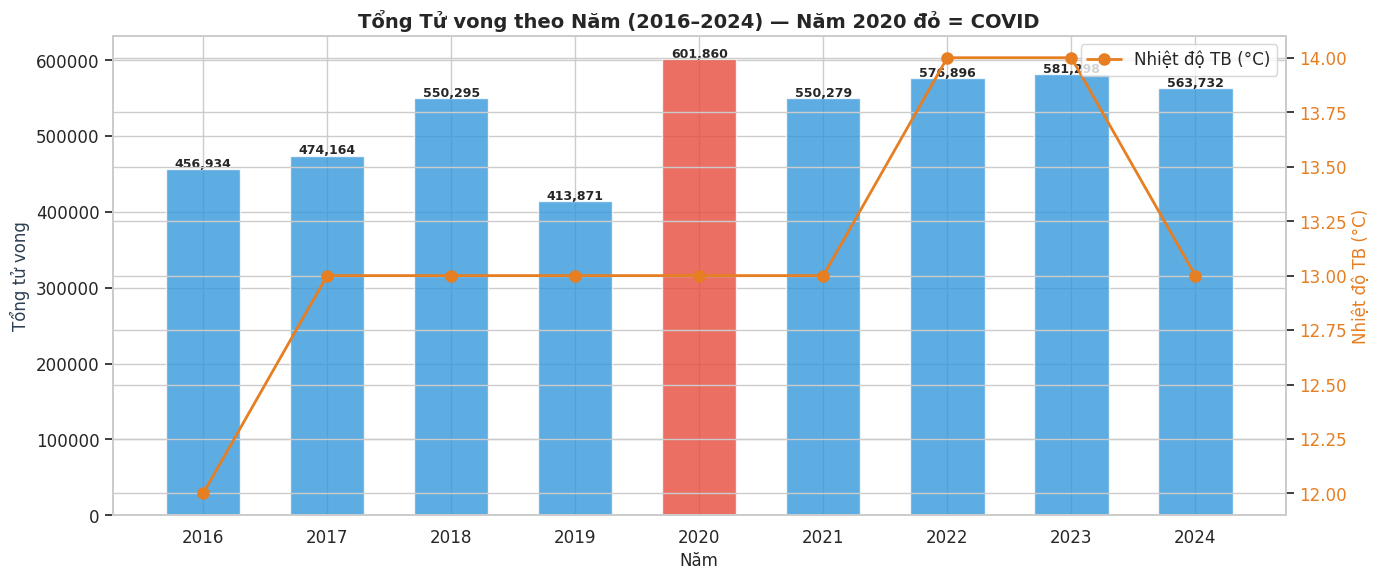

Tổng tử vong theo năm:
      total_deaths  weeks
year                     
2016      456934.0     45
2017      474164.0     46
2018      550295.0     53
2019      413871.0     41
2020      601860.0     52
2021      550279.0     49
2022      576896.0     52
2023      581298.0     52
2024      563732.0     52

→ Năm 2020 cao nhất: 601,860 ca (COVID-19)


In [5]:
yearly = df.groupby('year').agg(
    total_deaths=('deaths_total', 'sum'),
    avg_deaths=('deaths_total', 'mean'),
    avg_temp=('tasmax_mean_weekly_degC', 'mean'),
    weeks=('deaths_total', 'count')
).round(0)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar tổng tử vong
colors = ['#e74c3c' if y == 2020 else '#3498db' for y in yearly.index]
bars = ax1.bar(yearly.index, yearly['total_deaths'], color=colors, edgecolor='white',
               alpha=0.8, width=0.6)
ax1.set_xlabel('Năm', fontsize=12)
ax1.set_ylabel('Tổng tử vong', color='#2c3e50', fontsize=12)

# Ghi số lên bar
for bar, val in zip(bars, yearly['total_deaths']):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000,
             f'{val:,.0f}', ha='center', fontweight='bold', fontsize=9)

# Line nhiệt độ TB
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['avg_temp'], color='#e67e22', marker='o',
         linewidth=2, markersize=8, label='Nhiệt độ TB (°C)')
ax2.set_ylabel('Nhiệt độ TB (°C)', color='#e67e22', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#e67e22')

ax1.set_xticks(yearly.index)
ax2.legend(loc='upper right')
plt.title('Tổng Tử vong theo Năm (2016–2024) — Năm 2020 đỏ = COVID', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

print('Tổng tử vong theo năm:')
print(yearly[['total_deaths', 'weeks']].to_string())
print(f'\n→ Năm 2020 cao nhất: {yearly.loc[2020, "total_deaths"]:,.0f} ca (COVID-19)')

## 5.6 Violin Plot — Phân bố tử vong giữa các mùa

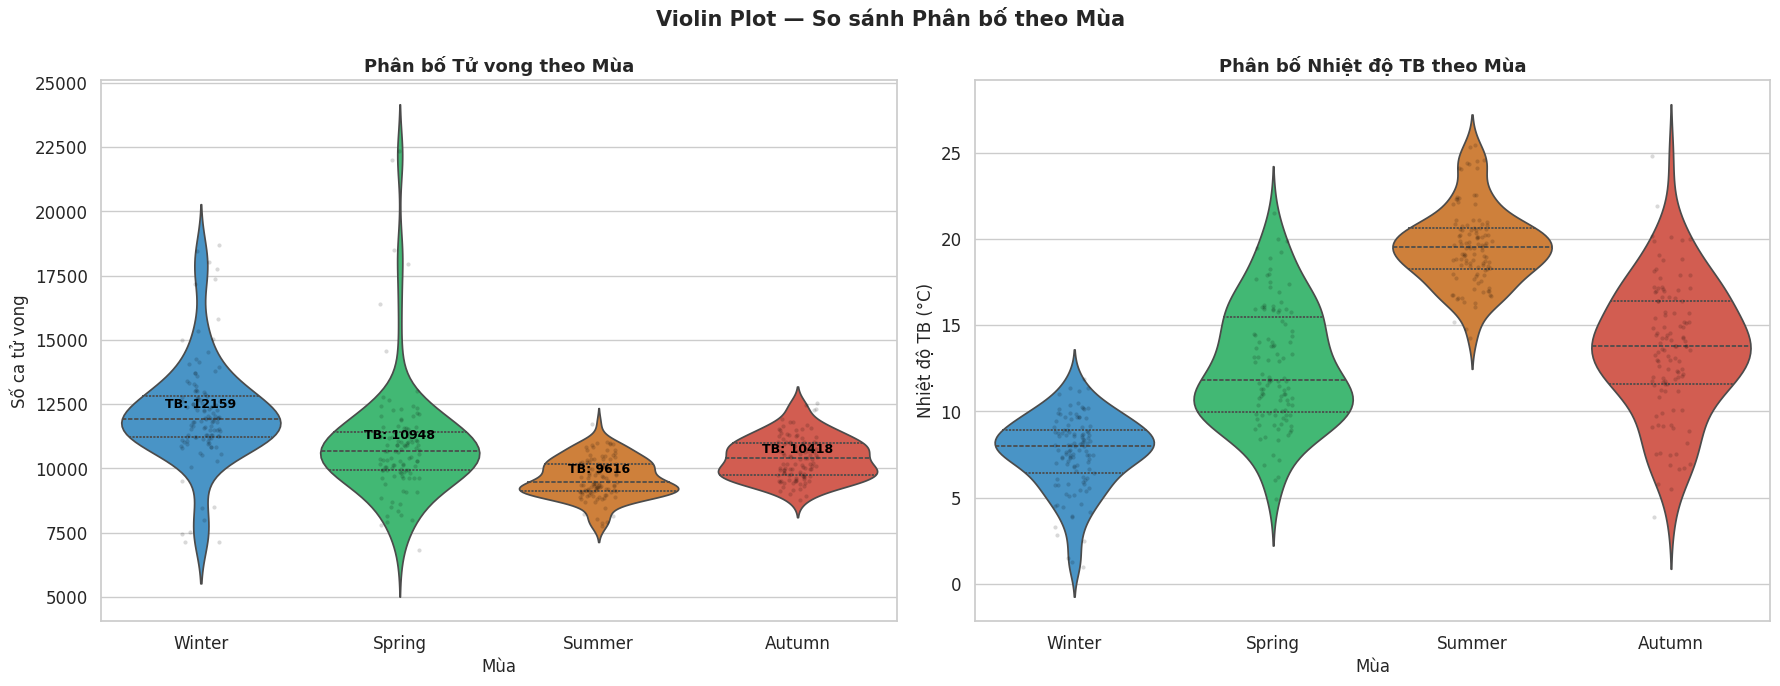

TB tử vong theo mùa:
  Winter  : Mean = 12159, Median = 11930, Std = 2064, n = 113
  Spring  : Mean = 10948, Median = 10687, Std = 2311, n = 107
  Summer  : Mean = 9616, Median = 9458, Std = 772, n = 111
  Autumn  : Mean = 10418, Median = 10388, Std = 833, n = 111


In [6]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
season_palette = {'Winter': '#3498db', 'Spring': '#2ecc71', 'Summer': '#e67e22', 'Autumn': '#e74c3c'}

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Violin plot tử vong
sns.violinplot(x='season', y='deaths_total', data=df, order=season_order,
               palette=season_palette, inner='quartile', ax=axes[0])
# Overlay với swarmplot (lấy mẫu nếu quá nhiều)
sns.stripplot(x='season', y='deaths_total', data=df, order=season_order,
              color='black', alpha=0.15, size=3, jitter=True, ax=axes[0])
axes[0].set_title('Phân bố Tử vong theo Mùa', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Mùa', fontsize=12)
axes[0].set_ylabel('Số ca tử vong', fontsize=12)

# Thêm mean annotations
means = df.groupby('season')['deaths_total'].mean()
for i, s in enumerate(season_order):
    axes[0].text(i, means[s] + 200, f'TB: {means[s]:.0f}', ha='center',
                 fontweight='bold', fontsize=9, color='black')

# Violin plot nhiệt độ
sns.violinplot(x='season', y='tasmax_mean_weekly_degC', data=df, order=season_order,
               palette=season_palette, inner='quartile', ax=axes[1])
sns.stripplot(x='season', y='tasmax_mean_weekly_degC', data=df, order=season_order,
              color='black', alpha=0.15, size=3, jitter=True, ax=axes[1])
axes[1].set_title('Phân bố Nhiệt độ TB theo Mùa', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Mùa', fontsize=12)
axes[1].set_ylabel('Nhiệt độ TB (°C)', fontsize=12)

plt.suptitle('Violin Plot — So sánh Phân bố theo Mùa', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print('TB tử vong theo mùa:')
for s in season_order:
    m = df[df['season']==s]['deaths_total']
    print(f'  {s:8s}: Mean = {m.mean():.0f}, Median = {m.median():.0f}, Std = {m.std():.0f}, n = {len(m)}')

## 5.7 Line Plot — Diễn biến Nhiệt độ & Tử vong qua các năm (các đỉnh peaks)

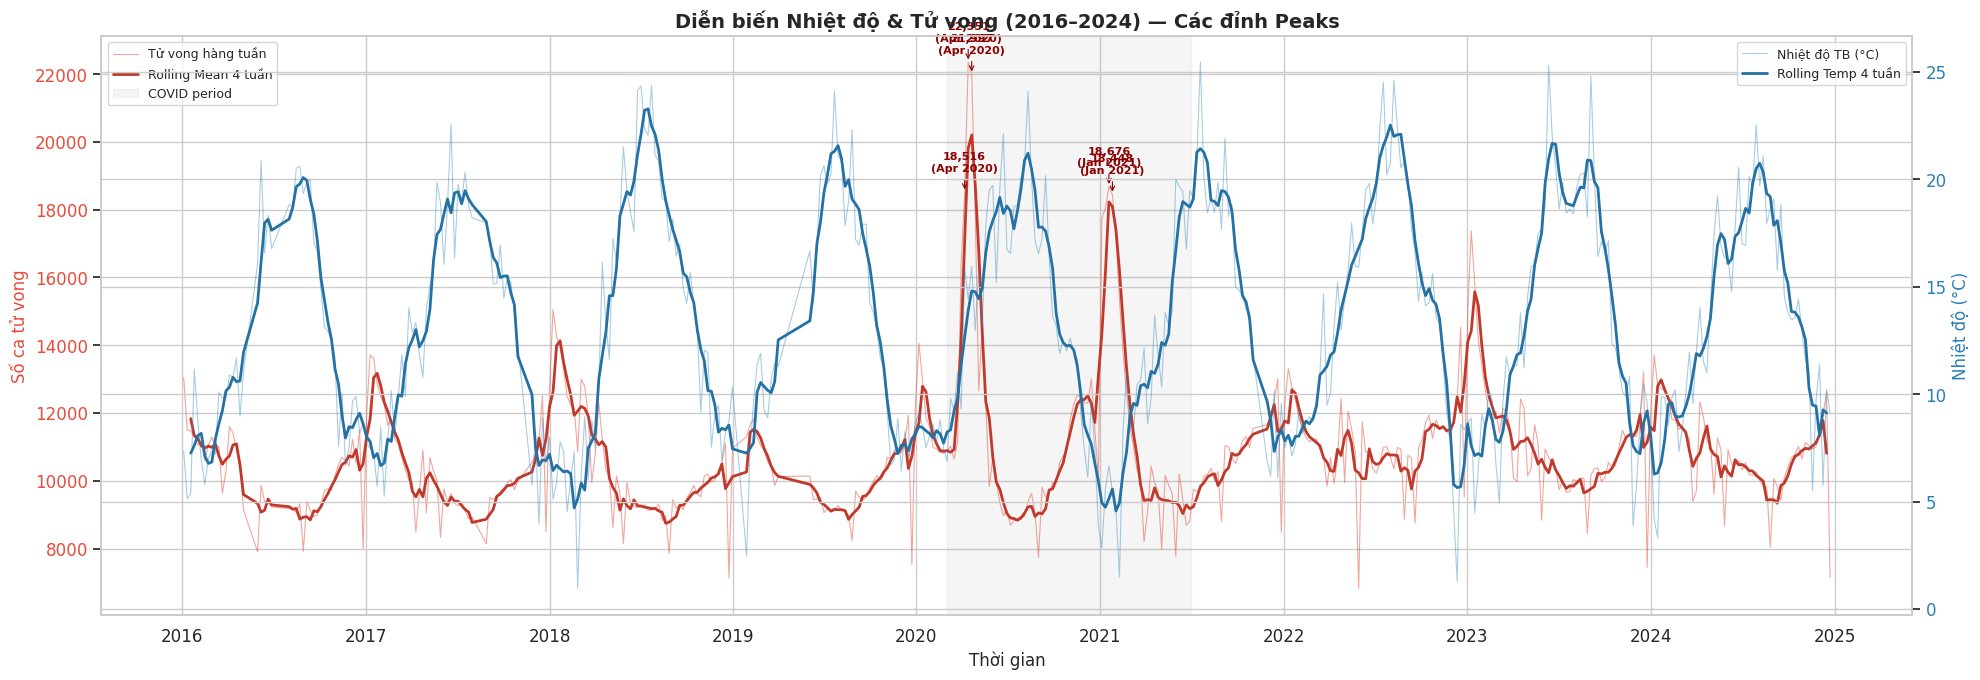

Top 5 tuần tử vong cao nhất:
week_start_mon  deaths_total  tasmax_mean_weekly_degC season
    2020-04-13       22351.0                14.414043 Spring
    2020-04-20       21997.0                15.959116 Spring
    2021-01-18       18676.0                 6.670256 Winter
    2020-04-06       18516.0                15.892410 Spring
    2021-01-25       18448.0                 5.451698 Winter


In [7]:
fig, ax1 = plt.subplots(figsize=(20, 7))

# Line tử vong
ax1.plot(df['week_start_mon'], df['deaths_total'], color='#e74c3c', alpha=0.5,
         linewidth=0.8, label='Tử vong hàng tuần')
# Rolling 4 tuần
rolling_4w = df['deaths_total'].rolling(4, center=True).mean()
ax1.plot(df['week_start_mon'], rolling_4w, color='#c0392b', linewidth=2,
         label='Rolling Mean 4 tuần')
ax1.set_ylabel('Số ca tử vong', color='#e74c3c', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#e74c3c')

# Line nhiệt độ
ax2 = ax1.twinx()
ax2.plot(df['week_start_mon'], df['tasmax_mean_weekly_degC'], color='#2980b9',
         alpha=0.4, linewidth=0.8, label='Nhiệt độ TB (°C)')
rolling_temp = df['tasmax_mean_weekly_degC'].rolling(4, center=True).mean()
ax2.plot(df['week_start_mon'], rolling_temp, color='#2471a3', linewidth=2,
         label='Rolling Temp 4 tuần')
ax2.set_ylabel('Nhiệt độ (°C)', color='#2980b9', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#2980b9')

# Highlight COVID
ax1.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2021-06-30'),
            alpha=0.08, color='gray', label='COVID period')

# Đánh dấu các đỉnh tử vong (top 5)
top5 = df.nlargest(5, 'deaths_total')
for _, row in top5.iterrows():
    ax1.annotate(f'{row["deaths_total"]:,.0f}\n({row["week_start_mon"].strftime("%b %Y")})',
                 xy=(row['week_start_mon'], row['deaths_total']),
                 xytext=(0, 15), textcoords='offset points',
                 fontsize=8, fontweight='bold', color='darkred',
                 arrowprops=dict(arrowstyle='->', color='darkred', lw=0.8),
                 ha='center')

ax1.set_xlabel('Thời gian', fontsize=12)
ax1.legend(loc='upper left', fontsize=9)
ax2.legend(loc='upper right', fontsize=9)
plt.title('Diễn biến Nhiệt độ & Tử vong (2016–2024) — Các đỉnh Peaks', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

print('Top 5 tuần tử vong cao nhất:')
print(top5[['week_start_mon', 'deaths_total', 'tasmax_mean_weekly_degC', 'season']].to_string(index=False))

## 5.8 Pie Chart — Tỷ lệ tuần Surge vs Normal

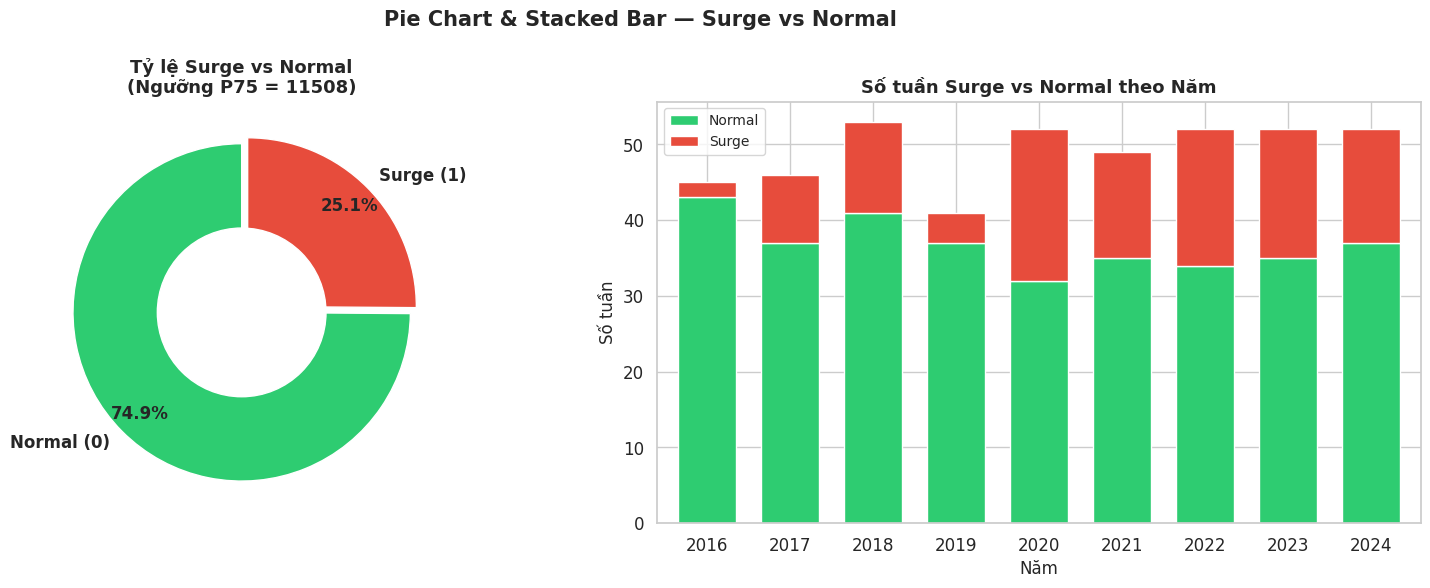

Normal: 331 tuần (74.9%)
Surge:  111 tuần (25.1%)

Surge theo năm:
      Normal  Surge
year               
2016      43      2
2017      37      9
2018      41     12
2019      37      4
2020      32     20
2021      35     14
2022      34     18
2023      35     17
2024      37     15


In [8]:
surge_counts = df['IsSurge'].value_counts().sort_index()
labels = ['Normal (0)', 'Surge (1)']
sizes = [surge_counts[0], surge_counts[1]]
colors_pie = ['#2ecc71', '#e74c3c']
explode = (0, 0.05)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Pie chart
wedges, texts, autotexts = axes[0].pie(sizes, labels=labels, colors=colors_pie, explode=explode,
                                        autopct='%1.1f%%', startangle=90, pctdistance=0.85,
                                        textprops={'fontsize': 12, 'fontweight': 'bold'})
centre_circle = plt.Circle((0, 0), 0.50, fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title(f'Tỷ lệ Surge vs Normal\n(Ngưỡng P75 = {df["deaths_total"].quantile(0.75):.0f})',
                   fontweight='bold', fontsize=13)

# Stacked bar theo năm
yearly_surge = df.groupby(['year', 'IsSurge']).size().unstack(fill_value=0)
yearly_surge.columns = ['Normal', 'Surge']
yearly_surge.plot(kind='bar', stacked=True, color=colors_pie, edgecolor='white',
                  ax=axes[1], width=0.7)
axes[1].set_title('Số tuần Surge vs Normal theo Năm', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Năm', fontsize=12)
axes[1].set_ylabel('Số tuần', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Pie Chart & Stacked Bar — Surge vs Normal', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Normal: {sizes[0]} tuần ({sizes[0]/len(df)*100:.1f}%)')
print(f'Surge:  {sizes[1]} tuần ({sizes[1]/len(df)*100:.1f}%)')
print(f'\nSurge theo năm:')
print(yearly_surge.to_string())

## 5.9 Pair Plot — Mối quan hệ giữa tất cả các cặp biến số

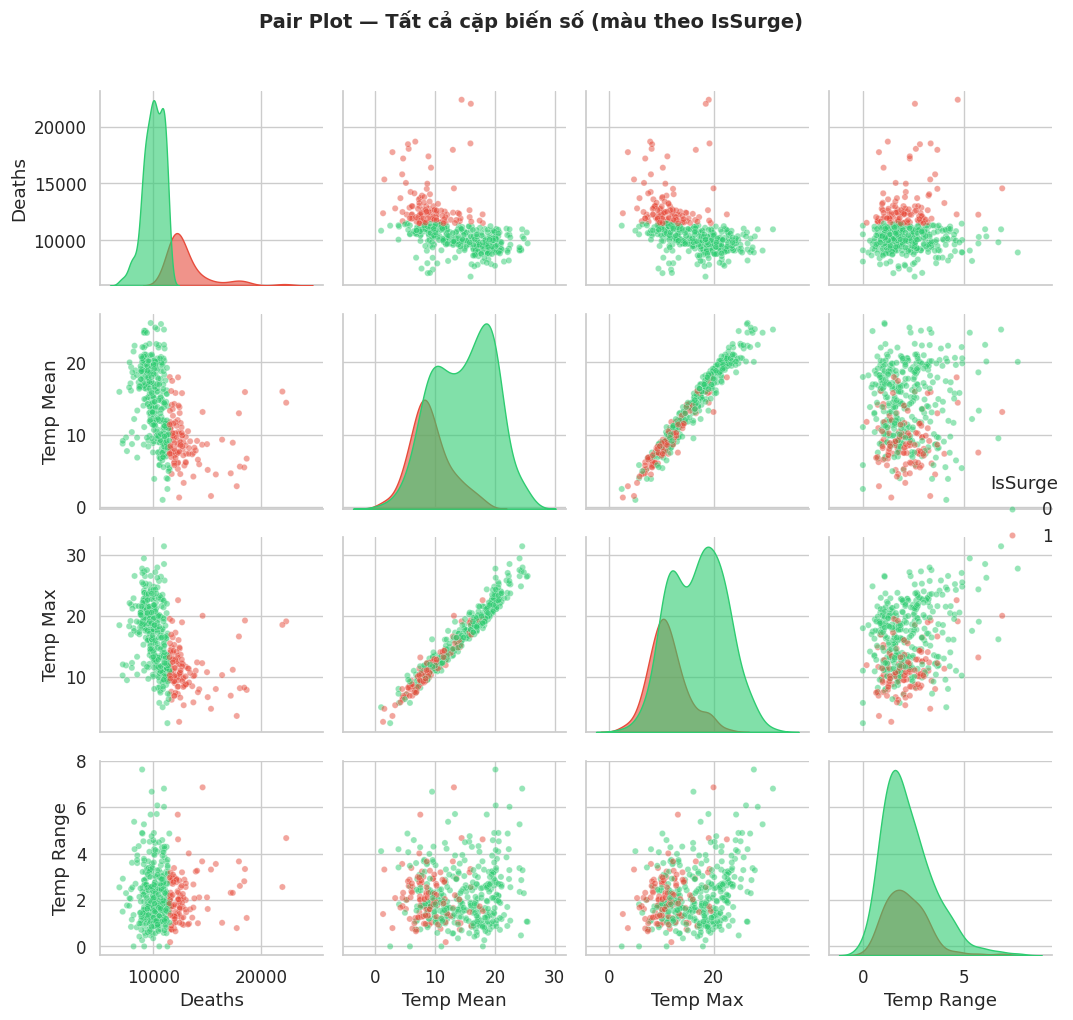

In [9]:
pair_cols = ['deaths_total', 'tasmax_mean_weekly_degC', 'tasmax_max_weekly_degC',
             'temp_range_weekly', 'IsSurge']
pair_labels = {'deaths_total': 'Deaths', 'tasmax_mean_weekly_degC': 'Temp Mean',
               'tasmax_max_weekly_degC': 'Temp Max', 'temp_range_weekly': 'Temp Range',
               'IsSurge': 'IsSurge'}

df_pair = df[pair_cols].rename(columns=pair_labels)

g = sns.pairplot(df_pair, hue='IsSurge', palette={0: '#2ecc71', 1: '#e74c3c'},
                 plot_kws={'alpha': 0.5, 's': 20, 'edgecolor': 'white', 'linewidth': 0.3},
                 diag_kws={'alpha': 0.6},
                 height=2.5, aspect=1)
g.figure.suptitle('Pair Plot — Tất cả cặp biến số (màu theo IsSurge)', fontweight='bold',
                   fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 5.10 Time Series Decomposition — Trend, Seasonality & Residual

> Decomposition requires a regularly spaced series, so it uses the **469-week prepared grid** only. The 27 interpolated weeks are never counted as observed registrations.


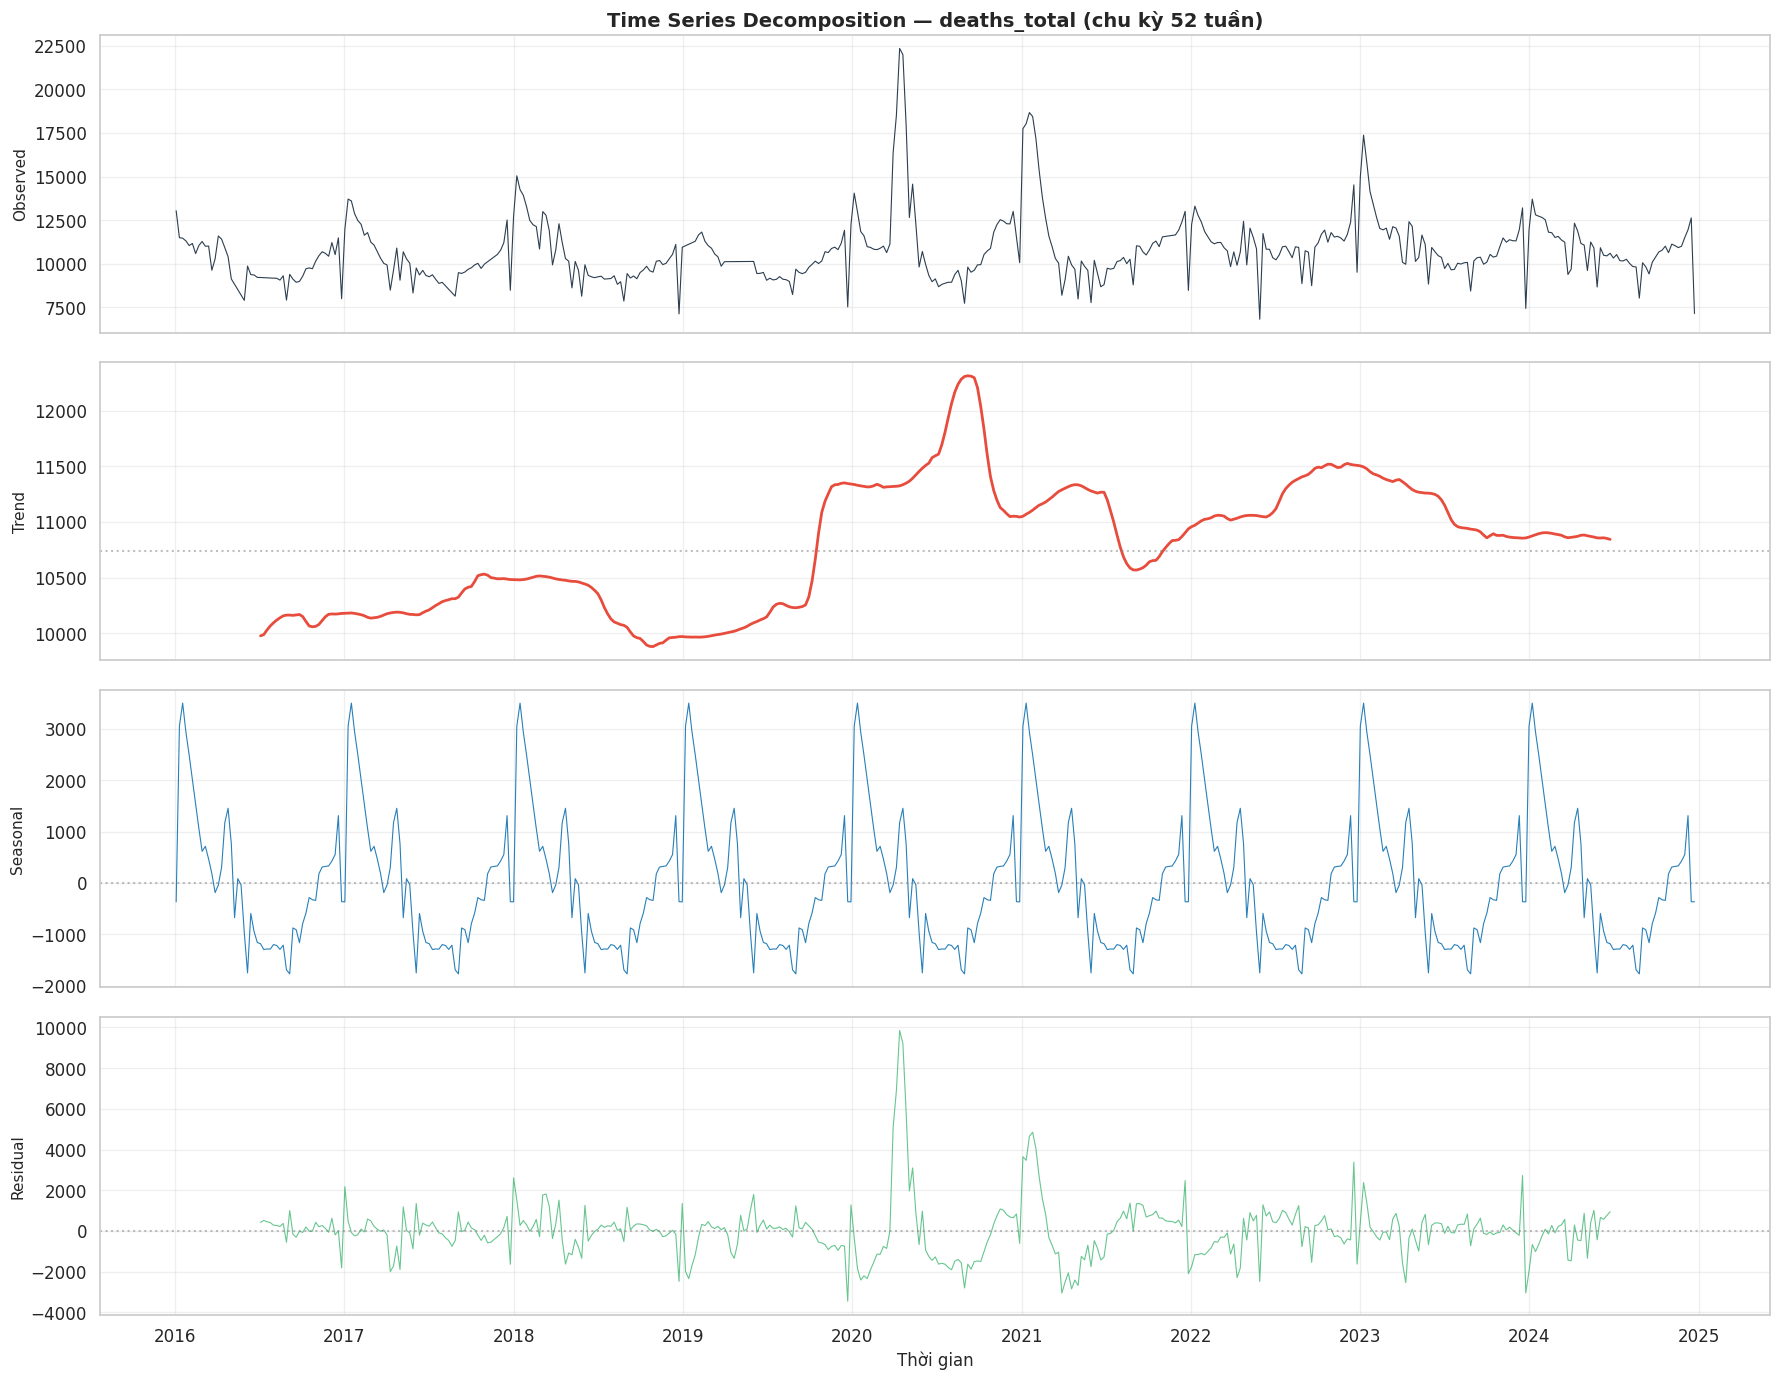

Residual — Mean: 6.1, Std: 1387.0
Residual — Min: -3448, Max: 9850
→ Residual lớn nhất tại COVID: thể hiện sự kiện bất thường không giải thích bằng trend/seasonal


In [10]:
# Decompose deaths_total (chu kỳ 52 tuần = 1 năm)
# Only decomposition uses the 469-row regular grid.
prepared_grid=pd.read_csv('uk_weather_health_weekly_CLEANED.csv',parse_dates=['week_start_mon'])
ts_deaths=prepared_grid.set_index('week_start_mon')['deaths_total'].sort_index().asfreq('W-MON')
assert len(ts_deaths)==469 and ts_deaths.notna().all()
decomp = seasonal_decompose(ts_deaths, model='additive', period=52)

fig, axes = plt.subplots(4, 1, figsize=(18, 14), sharex=True)

# Observed
axes[0].plot(decomp.observed, color='#2c3e50', linewidth=0.8)
axes[0].set_ylabel('Observed', fontsize=11)
axes[0].set_title('Time Series Decomposition — deaths_total (chu kỳ 52 tuần)',
                   fontweight='bold', fontsize=14)

# Trend
axes[1].plot(decomp.trend, color='#e74c3c', linewidth=2)
axes[1].set_ylabel('Trend', fontsize=11)
axes[1].axhline(ts_deaths.mean(), color='gray', linestyle=':', alpha=0.5)

# Seasonal
axes[2].plot(decomp.seasonal, color='#2980b9', linewidth=0.8)
axes[2].set_ylabel('Seasonal', fontsize=11)
axes[2].axhline(0, color='gray', linestyle=':', alpha=0.5)

# Residual
axes[3].plot(decomp.resid, color='#27ae60', linewidth=0.8, alpha=0.7)
axes[3].set_ylabel('Residual', fontsize=11)
axes[3].axhline(0, color='gray', linestyle=':', alpha=0.5)
axes[3].set_xlabel('Thời gian', fontsize=12)

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Phân tích residual
resid = decomp.resid.dropna()
print(f'Residual — Mean: {resid.mean():.1f}, Std: {resid.std():.1f}')
print(f'Residual — Min: {resid.min():.0f}, Max: {resid.max():.0f}')
print(f'→ Residual lớn nhất tại COVID: thể hiện sự kiện bất thường không giải thích bằng trend/seasonal')

## 5.11 Dashboard tương tác — Chọn năm xem chi tiết Thời tiết & Sức khỏe

Sử dụng **Plotly** để tạo dashboard tương tác.

**Ý nghĩa biến:** `tasmax_mean_weekly_degC` là nhiệt độ cực đại trung bình tuần (mean weekly Tmax). Nhãn “Nhiệt độ TB” cũ được đính chính thành “Tmax trung bình tuần” trong mã và biểu đồ tương tác.

In [11]:
# Dashboard tương tác với Plotly
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.08,
    subplot_titles=('Số ca tử vong hàng tuần', 'Tmax trung bình tuần (°C)')
)

# Thêm trace cho từng năm
years = sorted(df['year'].unique())
colors_plotly = px.colors.qualitative.Set1

for i, year in enumerate(years):
    df_y = df[df['year'] == year]
    color = colors_plotly[i % len(colors_plotly)]
    visible = True  # Tất cả hiện ban đầu

    # Deaths trace
    fig.add_trace(
        go.Scatter(x=df_y['week_start_mon'], y=df_y['deaths_total'],
                   name=f'{year} — Tử vong', mode='lines+markers',
                   line=dict(color=color, width=1.5),
                   marker=dict(size=4), visible=visible,
                   legendgroup=str(year), showlegend=True,
                   hovertemplate=f'Năm {year}<br>Tuần: %{{x|%d/%m/%Y}}<br>Tử vong: %{{y:,.0f}}<extra></extra>'),
        row=1, col=1
    )
    # Temperature trace
    fig.add_trace(
        go.Scatter(x=df_y['week_start_mon'], y=df_y['tasmax_mean_weekly_degC'],
                   name=f'{year} — Tmax', mode='lines+markers',
                   line=dict(color=color, width=1.5, dash='dot'),
                   marker=dict(size=4), visible=visible,
                   legendgroup=str(year), showlegend=False,
                   hovertemplate=f'Năm {year}<br>Tuần: %{{x|%d/%m/%Y}}<br>Tmax: %{{y:.1f}}°C<extra></extra>'),
        row=2, col=1
    )

# Tạo buttons để toggle từng năm
buttons = []
n_years = len(years)

# Button "Tất cả"
buttons.append(dict(
    label='Tất cả', method='update',
    args=[{'visible': [True] * (n_years * 2)}]
))

# Button cho từng năm
for i, year in enumerate(years):
    visibility = [False] * (n_years * 2)
    visibility[i * 2] = True      # deaths trace
    visibility[i * 2 + 1] = True  # temp trace
    buttons.append(dict(
        label=str(year), method='update',
        args=[{'visible': visibility}]
    ))

fig.update_layout(
    updatemenus=[dict(
        type='buttons', direction='right',
        x=0.0, xanchor='left', y=1.15, yanchor='top',
        buttons=buttons,
        bgcolor='#f0f0f0', bordercolor='#ccc',
        font=dict(size=11)
    )],
    title=dict(text='Dashboard tương tác — Thời tiết & Sức khỏe theo Năm',
               font=dict(size=16)),
    height=650,
    hovermode='x unified',
    legend=dict(orientation='h', yanchor='bottom', y=-0.2, xanchor='center', x=0.5,
                font=dict(size=9)),
    template='plotly_white'
)

fig.update_yaxes(title_text='Số ca tử vong', row=1, col=1)
fig.update_yaxes(title_text='Tmax trung bình tuần (°C)', row=2, col=1)
fig.update_xaxes(title_text='Thời gian', row=2, col=1)

fig.show()
print('→ Bấm nút năm ở góc trên để lọc. Hover để xem chi tiết từng tuần.')

→ Bấm nút năm ở góc trên để lọc. Hover để xem chi tiết từng tuần.


## 5.12 Tổng kết Visualization

In [12]:
print('=' * 70)
print('TỔNG KẾT VISUALIZATION — NOTEBOOK 5')
print('=' * 70)
peak_death_row = df.loc[df['deaths_total'].idxmax()]
peak_tmax_row = df.loc[df['tasmax_mean_weekly_degC'].idxmax()]
print('1. Nhiệt độ trong notebook là mean weekly Tmax, không phải nhiệt độ trung bình thông thường.')
print('2. Mortality và Tmax có chu kỳ mùa đối nhau; tương quan mô tả không xác lập quan hệ nhân quả.')
print(f"3. Đỉnh tử vong: {peak_death_row['deaths_total']:,.0f} ca, tuần {peak_death_row['week_start_mon']:%d/%m/%Y}.")
print(f"4. Tmax tuần cao nhất: {peak_tmax_row['tasmax_mean_weekly_degC']:.2f}°C, tuần {peak_tmax_row['week_start_mon']:%d/%m/%Y}.")
print('5. Đuôi tử vong cao chịu ảnh hưởng COVID; số tuần cực nóng ít, nên không khẳng định một đường cong nguy cơ ổn định.')
print('6. Winter có mức tử vong trung tâm cao hơn Summer; cần đặt cạnh bối cảnh dịch bệnh và lịch đăng ký.')
print('7. IsSurge là biến dẫn xuất phục vụ khám phá, không phải ngưỡng cảnh báo y tế đã được thẩm định.')
print('8. Các phần 5.1–5.12 là biểu đồ khám phá; phần 5.13 tái tạo các hình dùng trong bài báo với nguồn dữ liệu tương ứng.')
print('9. Các số headline của bài báo phải đối chiếu observed table, không gọi mọi dòng prepared là tuần quan sát.')
print('10. Dashboard Plotly cho phép chọn năm và xem giá trị từng tuần; regional Tmax chỉ là bối cảnh exposure.')
print('=' * 70)


TỔNG KẾT VISUALIZATION — NOTEBOOK 5
1. Nhiệt độ trong notebook là mean weekly Tmax, không phải nhiệt độ trung bình thông thường.
2. Mortality và Tmax có chu kỳ mùa đối nhau; tương quan mô tả không xác lập quan hệ nhân quả.
3. Đỉnh tử vong: 22,351 ca, tuần 13/04/2020.
4. Tmax tuần cao nhất: 25.45°C, tuần 19/07/2021.
5. Đuôi tử vong cao chịu ảnh hưởng COVID; số tuần cực nóng ít, nên không khẳng định một đường cong nguy cơ ổn định.
6. Winter có mức tử vong trung tâm cao hơn Summer; cần đặt cạnh bối cảnh dịch bệnh và lịch đăng ký.
7. IsSurge là biến dẫn xuất phục vụ khám phá, không phải ngưỡng cảnh báo y tế đã được thẩm định.
8. Các phần 5.1–5.12 là biểu đồ khám phá; phần 5.13 tái tạo các hình dùng trong bài báo với nguồn dữ liệu tương ứng.
9. Các số headline của bài báo phải đối chiếu observed table, không gọi mọi dòng prepared là tuần quan sát.
10. Dashboard Plotly cho phép chọn năm và xem giá trị từng tuần; regional Tmax chỉ là bối cảnh exposure.


---
*Trước: [4. Data Analysis with Python](./4.%20Data%20Analysis%20with%20Python.ipynb)* | *Next: [6. Regression Analysis](./6.Regression_Analysis.ipynb)*

## 5.13 Đối chiếu với bài báo — các hình chính của phần mô tả

Từ đây trở xuống là phần **bổ sung để tái tạo đúng các hình đã dùng trong bài báo**. Toàn bộ các ô gốc 5.1–5.12 ở phía trên được giữ nguyên. Các nhãn bên trong hình giữ tiếng Anh vì cần khớp trực tiếp với bài báo; phần giải thích ngoài mã lệnh dùng tiếng Việt.


In [13]:
from pathlib import Path

def locate_paper_support(relative_path):
    # Accept a self-contained project folder OR the original paper_support/data layout.
    relative_path = Path(relative_path)
    candidates = []
    for root in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
        candidates.extend([
            root / relative_path.name,
            root / relative_path,
            root / 'paper_support' / relative_path,
            root / 'Datasets' / 'Observed' / relative_path.name,
            root / 'Datasets' / 'Prepared' / relative_path.name,
            root / 'Datasets' / 'Regional_Reference' / relative_path.name,
            root / 'Datasets' / 'Documentation' / relative_path.name,
        ])
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(
        f'Missing data file: {relative_path.name}. Put all six notebooks and the five supplied datasets in the same folder. '
        f'Current directory: {Path.cwd()}'
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import patches, colors
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D

CORAL = '#F28E79'
CORAL_DARK = '#D96652'
BLUE = '#72B7D2'
BLUE_DARK = '#2D74A6'
BLUE_LIGHT = '#DCEEF7'
YELLOW = '#F7E7A9'
GREY = '#777777'
LIGHT_GREY = '#E6E6E6'
DARK = '#333333'

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.labelsize': 8, 'axes.titlesize': 8,
    'xtick.labelsize': 7, 'ytick.labelsize': 7,
    'legend.fontsize': 7, 'axes.linewidth': 0.7,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.03,
})

import json
paper_raw = pd.read_csv(locate_paper_support('data/uk_weather_health_weekly_2016_2024_TOTAL_FINAL.csv'),
                        parse_dates=['week_start_sat','week_start_mon','week_end']).sort_values('week_start_mon').reset_index(drop=True)
paper_raw['month'] = paper_raw['week_start_mon'].dt.month
season_map = {12:'Winter',1:'Winter',2:'Winter',3:'Spring',4:'Spring',5:'Spring',6:'Summer',7:'Summer',8:'Summer',9:'Autumn',10:'Autumn',11:'Autumn'}
paper_raw['season'] = paper_raw['month'].map(season_map)


### Hình 1 — Phân bố tử vong và nhiệt độ theo mùa

Hình 1 đặt hai biến lên cùng khung mùa. Râu của boxplot dùng **phân vị 5%–95%**, dấu hình thoi là mean và đường trong hộp là median.


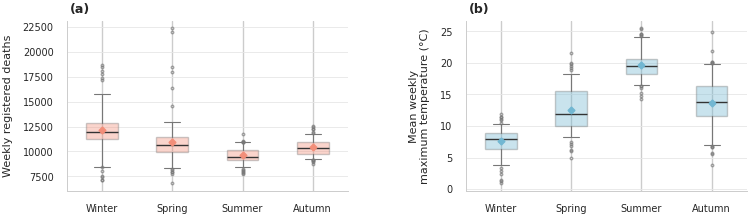

In [14]:
order = ['Winter','Spring','Summer','Autumn']
deaths = [paper_raw.loc[paper_raw['season'].eq(s),'deaths_total'].to_numpy() for s in order]
temps = [paper_raw.loc[paper_raw['season'].eq(s),'tasmax_mean_weekly_degC'].to_numpy() for s in order]
fig, axes = plt.subplots(1,2,figsize=(7.35,2.18),gridspec_kw={'wspace':0.42})
for ax, values, color, ylabel in [
    (axes[0], deaths, CORAL, 'Weekly registered deaths'),
    (axes[1], temps, BLUE, 'Mean weekly\nmaximum temperature (°C)')]:
    bp=ax.boxplot(values,labels=order,whis=(5,95),showmeans=True,patch_artist=True,
                  meanprops={'marker':'D','markersize':3.5,'markerfacecolor':color,'markeredgecolor':color},
                  medianprops={'color':DARK,'linewidth':1.0},whiskerprops={'color':GREY,'linewidth':0.8},
                  capprops={'color':GREY,'linewidth':0.8},
                  flierprops={'marker':'o','markersize':1.8,'markerfacecolor':'none','markeredgecolor':GREY,'alpha':0.65})
    for patch in bp['boxes']:
        patch.set_facecolor(color); patch.set_edgecolor(GREY); patch.set_alpha(0.38)
    ax.set_ylabel(ylabel,labelpad=7); ax.grid(axis='y',color=LIGHT_GREY,linewidth=0.6); ax.spines[['top','right']].set_visible(False)
axes[0].text(0.01,1.03,'(a)',transform=axes[0].transAxes,ha='left',va='bottom',fontweight='bold',fontsize=9,clip_on=False)
axes[1].text(0.01,1.03,'(b)',transform=axes[1].transAxes,ha='left',va='bottom',fontweight='bold',fontsize=9,clip_on=False)
fig.subplots_adjust(left=0.07,right=0.995,bottom=0.20,top=0.98,wspace=0.42)
plt.show()


**Đối chiếu với bài báo:** mùa đông có mức tử vong trung tâm cao nhất; mùa hè thấp nhất. Mùa xuân có đuôi trên rộng do chứa làn sóng COVID-19 đầu tiên. Nhiệt độ thì thể hiện thứ tự mùa rõ ràng theo chiều ngược với tử vong.


### Hình 3 — Chuỗi tử vong và nhiệt độ theo tuần

Đây là **bản Hình 3 cuối cùng đã dùng trong bài báo**, gồm khoảng cách rõ giữa hai biểu đồ con để nhãn `25.45°C` không chạm biểu đồ phía trên.

- vùng vàng: giai đoạn nhiễu lớn của đại dịch;
- vùng xanh: tập kiểm tra giữ lại dùng cho hồi quy;
- hai đường đều là **giá trị quan sát thật**.


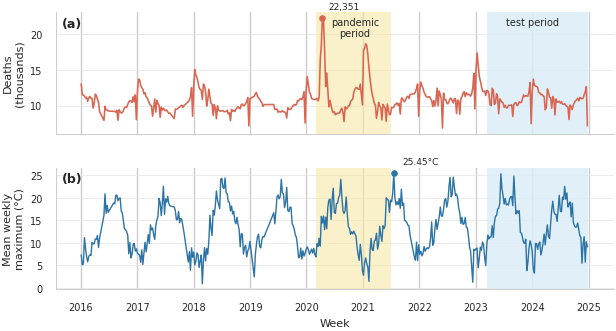

In [15]:
fig, axes = plt.subplots(2,1,figsize=(7.2,3.6),sharex=True,gridspec_kw={'hspace':0.28})
start_pandemic=pd.Timestamp('2020-03-01'); end_pandemic=pd.Timestamp('2021-06-30')
test_start=pd.Timestamp('2023-03-13'); test_end=paper_raw['week_start_mon'].max()+pd.Timedelta(days=7)
for ax in axes:
    ax.axvspan(start_pandemic,end_pandemic,color=YELLOW,alpha=0.62,linewidth=0)
    ax.axvspan(test_start,test_end,color=BLUE_LIGHT,alpha=0.85,linewidth=0)
    ax.grid(axis='y',color=LIGHT_GREY,linewidth=0.55); ax.spines[['top','right']].set_visible(False)
axes[0].plot(paper_raw['week_start_mon'],paper_raw['deaths_total']/1000,color=CORAL_DARK,lw=1.15)
axes[1].plot(paper_raw['week_start_mon'],paper_raw['tasmax_mean_weekly_degC'],color=BLUE_DARK,lw=1.0)
axes[0].set_ylabel('Deaths\n(thousands)'); axes[1].set_ylabel('Mean weekly\nmaximum (°C)'); axes[1].set_xlabel('Week')
axes[0].text(0.01,0.96,'(a)',transform=axes[0].transAxes,ha='left',va='top',fontweight='bold',fontsize=9)
axes[1].text(0.01,0.96,'(b)',transform=axes[1].transAxes,ha='left',va='top',fontweight='bold',fontsize=9)
y0_low,y0_high=axes[0].get_ylim(); label_y=y0_low+0.96*(y0_high-y0_low)
axes[0].text(pd.Timestamp('2020-11-10'),label_y,'pandemic\nperiod',ha='center',va='top',fontsize=7)
axes[0].text(pd.Timestamp('2024-01-01'),label_y,'test period',ha='center',va='top',fontsize=7)
i_death=paper_raw['deaths_total'].idxmax()
axes[0].scatter(paper_raw.loc[i_death,'week_start_mon'],paper_raw.loc[i_death,'deaths_total']/1000,s=14,color=CORAL_DARK,zorder=4)
axes[0].annotate(f"{int(paper_raw.loc[i_death,'deaths_total']):,}",(paper_raw.loc[i_death,'week_start_mon'],paper_raw.loc[i_death,'deaths_total']/1000),xytext=(4,6),textcoords='offset points',fontsize=6.5)
i_temp=paper_raw['tasmax_mean_weekly_degC'].idxmax()
axes[1].scatter(paper_raw.loc[i_temp,'week_start_mon'],paper_raw.loc[i_temp,'tasmax_mean_weekly_degC'],s=14,color=BLUE_DARK,zorder=4)
axes[1].annotate(f"{paper_raw.loc[i_temp,'tasmax_mean_weekly_degC']:.2f}°C",(paper_raw.loc[i_temp,'week_start_mon'],paper_raw.loc[i_temp,'tasmax_mean_weekly_degC']),xytext=(6,5),textcoords='offset points',fontsize=6.5,va='bottom')
axes[1].xaxis.set_major_locator(mdates.YearLocator()); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.show()


**Các mốc cần nhớ:** đỉnh tử vong là **22.351 ca vào tháng 4/2020**; tuần nóng nhất đạt **25,45°C vào tháng 7/2021**. Mùa đông trung bình khoảng **12.159 ca/tuần ở 7,59°C**, còn mùa hè khoảng **9.616 ca/tuần ở 19,59°C**. Quan hệ nghịch ở đây là mô tả, không phải bằng chứng nhân quả.


### Hình 5 — Nhiệt độ cực đại theo vùng năm 2024

Hình này dùng bảng Met Office riêng cho **England N, England S và Wales**. Nó chỉ bổ sung **bối cảnh không gian của nhiệt độ**, không gán số tử vong quốc gia cho từng vùng.


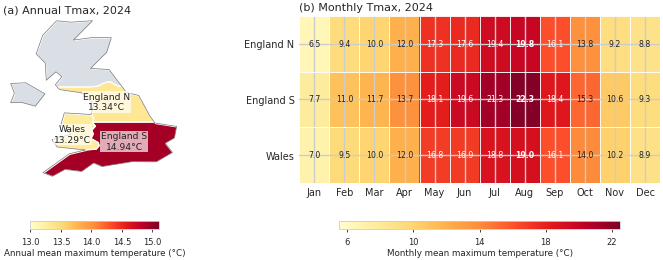

In [16]:
# Install Shapely into this notebook's active Python kernel only if it is missing.
# Shapely is used to clip the UK GeoJSON shapes for Figure 5 (regional Tmax map).
try:
    from shapely.geometry import shape, Polygon, box, MultiPolygon, GeometryCollection
except ModuleNotFoundError as exc:
    if not (exc.name == 'shapely' or exc.name.startswith('shapely.')):
        raise
    import subprocess
    import sys
    print('Shapely is missing in this Jupyter kernel; installing shapely>=2,<3...')
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shapely>=2.0,<3.0'])
    except subprocess.CalledProcessError as err:
        raise RuntimeError(
            'Could not install Shapely automatically. Run `%pip install shapely` in a '
            'notebook cell with an internet connection, restart the kernel, then Run All.'
        ) from err
    from shapely.geometry import shape, Polygon, box, MultiPolygon, GeometryCollection
regional = pd.read_csv(locate_paper_support('data/metoffice_general_regions_tmax_2024.csv'))
geo = json.loads(locate_paper_support('data/united_kingdom_outline.geojson').read_text(encoding='utf-8'))
uk = shape(geo['features'][0]['geometry']); ni, gb = sorted(list(uk.geoms), key=lambda g:g.area)
anglo_scottish = Polygon([(-8.0,49.0),(3.0,49.0),(3.0,55.00),(-1.55,55.00),(-1.78,55.10),(-2.08,55.27),(-2.42,55.18),(-2.72,55.02),(-3.18,54.96),(-8.0,54.96)])
england_wales = gb.intersection(anglo_scottish)
wales_mask = Polygon([(-6.70,51.25),(-6.70,53.70),(-3.10,53.70),(-3.10,53.45),(-2.98,53.20),(-3.04,52.98),(-2.88,52.78),(-3.08,52.56),(-3.00,52.34),(-3.13,52.09),(-2.72,51.86),(-2.67,51.69),(-2.83,51.50),(-6.70,51.25)])
wales=england_wales.intersection(wales_mask); england=england_wales.difference(wales)
england_n=england.intersection(box(-8,53.0,3,56)); england_s=england.intersection(box(-8,49.0,3,53.0)); other_gb=gb.difference(england_wales)
region_geoms={'England N':england_n,'England S':england_s,'Wales':wales}; annual=regional.set_index('region')['Annual'].to_dict()
def polygon_patches(geom):
    output=[]
    if geom.is_empty: return output
    if isinstance(geom,Polygon): output.append(patches.Polygon(np.asarray(geom.exterior.coords),closed=True))
    elif isinstance(geom,(MultiPolygon,GeometryCollection)):
        for part in geom.geoms: output.extend(polygon_patches(part))
    return output
def draw_geom(ax,geom,facecolor,edgecolor='white',linewidth=0.7,zorder=1):
    poly=polygon_patches(geom)
    if poly: ax.add_collection(PatchCollection(poly,facecolor=facecolor,edgecolor=edgecolor,linewidth=linewidth,zorder=zorder))
fig=plt.figure(figsize=(7.35,2.78),facecolor='white'); gs=fig.add_gridspec(1,2,width_ratios=[0.41,0.59],wspace=0.26)
ax=fig.add_subplot(gs[0,0]); ax.set_aspect('equal'); ax.axis('off'); grey='#D9DFE5'
draw_geom(ax,ni,grey,edgecolor='white',linewidth=0.65); draw_geom(ax,other_gb,grey,edgecolor='white',linewidth=0.65)
cmap=plt.get_cmap('YlOrRd'); norm=colors.Normalize(vmin=13.0,vmax=15.1)
for name,geom in region_geoms.items(): draw_geom(ax,geom,cmap(norm(annual[name])),edgecolor='white',linewidth=0.95,zorder=3)
draw_geom(ax,gb,'none',edgecolor='#777777',linewidth=0.5,zorder=4); draw_geom(ax,ni,'none',edgecolor='#777777',linewidth=0.5,zorder=4)
label_pos={'England N':(-2.25,54.10),'England S':(-1.25,51.90),'Wales':(-4.15,52.30)}
for name,(xx,yy) in label_pos.items():
    ax.text(xx,yy,f'{name}\n{annual[name]:.2f}°C',ha='center',va='center',fontsize=6.6,color='#222222',zorder=6,bbox=dict(facecolor='white',edgecolor='none',alpha=0.68,pad=0.7))
ax.set_xlim(-8.0,2.2); ax.set_ylim(49.6,58.9); ax.set_title('(a) Annual Tmax, 2024',loc='left',pad=2,fontweight='normal')
ax2=fig.add_subplot(gs[0,1]); months=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
vals=regional.set_index('region').loc[['England N','England S','Wales'],months].to_numpy(float); heat_norm=colors.Normalize(vmin=5.5,vmax=22.5)
im=ax2.imshow(vals,cmap='YlOrRd',norm=heat_norm,aspect='auto'); ax2.set_xticks(np.arange(len(months)),labels=months); ax2.set_yticks(np.arange(3),labels=['England N','England S','Wales']); ax2.tick_params(length=0)
ax2.set_title('(b) Monthly Tmax, 2024',loc='left',pad=4,fontweight='normal')
for spine in ax2.spines.values(): spine.set_visible(False)
for i in range(vals.shape[0]):
    max_j=int(np.nanargmax(vals[i]))
    for j in range(vals.shape[1]):
        rgba=cmap(heat_norm(vals[i,j])); lum=0.299*rgba[0]+0.587*rgba[1]+0.114*rgba[2]
        ax2.text(j,i,f'{vals[i,j]:.1f}',ha='center',va='center',fontsize=5.55,color=('white' if lum<0.52 else '#222222'),fontweight=('bold' if j==max_j else 'normal'))
ax2.set_xticks(np.arange(-0.5,len(months),1),minor=True); ax2.set_yticks(np.arange(-0.5,3,1),minor=True); ax2.grid(which='minor',color='white',linewidth=0.65); ax2.tick_params(which='minor',bottom=False,left=False)
fig.subplots_adjust(left=0.045,right=0.985,top=0.86,bottom=0.26)
pos=ax.get_position(); cax=fig.add_axes([pos.x0+0.15*pos.width,0.092,0.70*pos.width,0.032]); cb=plt.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,orientation='horizontal'); cb.set_ticks([13.0,13.5,14.0,14.5,15.0]); cb.ax.tick_params(labelsize=6.0,length=2); cb.set_label('Annual mean maximum temperature (°C)',labelpad=1.4,fontsize=6.3); cb.outline.set_linewidth(0.6)
pos2=ax2.get_position(); cax2=fig.add_axes([pos2.x0+0.11*pos2.width,0.092,0.78*pos2.width,0.032]); cb2=plt.colorbar(im,cax=cax2,orientation='horizontal'); cb2.set_ticks([6,10,14,18,22]); cb2.ax.tick_params(labelsize=6.0,length=2); cb2.set_label('Monthly mean maximum temperature (°C)',labelpad=1.4,fontsize=6.3); cb2.outline.set_linewidth(0.6)
plt.show()


**Đối chiếu với bài báo:** England S ấm nhất trong năm; England N và Wales gần nhau hơn, và cả ba vùng đều đạt mức cao nhất vào tháng 8. Vì dữ liệu tử vong chỉ có ở mức England & Wales toàn quốc, Hình 5 **không phải bản đồ nguy cơ tử vong vùng**.


## Final checks / Verification

The following assertions are executable checks, not manually entered model results.

In [17]:
assert len(df)==442 and len(ts_deaths)==469 and len(regional)==3
print('PASS: observed charts, 469-grid decomposition, regional Tmax.')

PASS: observed charts, 469-grid decomposition, regional Tmax.
